# PLS-DA analysis tutorial

### Import the required packages

In [1]:
!git clone https://github.com/MarinaAth/metabolomics-course-ebi.git
%cd metabolomics-course-ebi

Cloning into 'metabolomics-course-ebi'...
remote: Enumerating objects: 119, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 119 (delta 60), reused 71 (delta 32), pack-reused 13 (from 1)
Receiving objects: 100% (119/119), 58.98 MiB | 11.91 MiB/s, done.
Resolving deltas: 100% (62/62), done.
/content/metabolomics-course-ebi


In [2]:
import pandas as pds
import numpy as np
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, RocCurveDisplay, r2_score
from sklearn.pipeline import Pipeline
import plotly.express as px
from scipy.stats import f as f_distribution

### Load the example dataset using pandas

In [3]:
lcMSData = pds.read_csv('./Data/Dementia_RPOS_XCMS_Dataset.csv')

In [4]:
# Read the retention time and m/z value from feature names
featuresData = pds.DataFrame([(float(x.split('_')[0]), float(x.split('_')[1][:-3])) for x in lcMSData.columns[5:]], columns=['Rt', 'mz'])
featuresData['Rt'] = featuresData['Rt']/60
medianSpectrum = np.median(lcMSData.iloc[:, 5:].values, axis=0)

# Use log of median spectra as intensity value for the scatterplot
featuresData['Median'] = np.log(medianSpectrum + 1)
#featuresData['Median'] = medianSpectrum

In [5]:
fig = px.scatter(featuresData, x="Rt", y="mz", color="Median", render_mode='webgl',
                color_continuous_scale='RdBu',
                labels={"Rt": "Retention time (min)",
                        "mz": "m/z"},
                template='plotly_white')

fig.show()

## PLS-DA model

The first step in a PLS-DA model is to fit a PLS regression model with a dummy vector/matrix encoding class membership as Y.

In [6]:
# Select only the MS features
XDataMatrix = lcMSData.iloc[:, 5:].values

# Log transform the data matrix
logXDataMatrix = np.log(XDataMatrix + 1)

# Encode Gender as a numeric dummy variable using pandas Categorical.
# .codes assigns integers in the order of .categories, which are sorted
# alphabetically by default: Female=0, Male=1.
# Run YGender.categories in the next cell to verify the encoding.
YGender = pds.Categorical(lcMSData['Gender'].values)
YGenderDummy = YGender.codes

In [7]:
# pandas Categorical object associates the "categories" text name with a numerical code
# The numerical code follows the order in the .categories index
YGender.categories

Index(['Female', 'Male'], dtype='object')

The YGenderDummy vector is now a vector of 0s and 1s, where 0=Female and 1=Male

In [8]:
YGenderDummy

array([0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0], dtype=int8)

In [9]:
# Regular apply PLS with dummy vector as Y
plsModel = Pipeline(steps=[('uv_scale', StandardScaler()), ('PLS', PLSRegression(n_components=2, scale=False))])

plsModel.fit(logXDataMatrix, YGenderDummy)

Pipeline(steps=[('uv_scale', StandardScaler()),
                ('PLS', PLSRegression(scale=False))])

### PLS-DA model prediction

The predictions of a PLS regression model is a continuous value. To convert this number into a class prediction, we need an extra classification rule or algorithm. The simplest procedure is to assign the class membership which is closest to the predicted value. For example, the class will be 0 (Female) if prediction < 0.5, or Male if > 0.5.

In [10]:
predictFrame = pds.DataFrame(np.c_[plsModel.predict(logXDataMatrix), YGenderDummy], columns=['Predicted', 'Gender'])

fig = px.scatter(predictFrame, x="Predicted", y="Gender", render_mode='webgl',
                labels={"Predicted": "PLS predicted Gender",
                        "Gender": "Gender"},
                template='plotly_white')

fig.add_vline(x=0.5, line_dash="dash")

fig.show()

We will instead convert the PLS outputs into a class prediction using a logistic regression model. The class will be predicted with the logistic regression model using the PLS T-scores (class ~ PLS scores).

'ROC AUC: 0.9968820861678004'

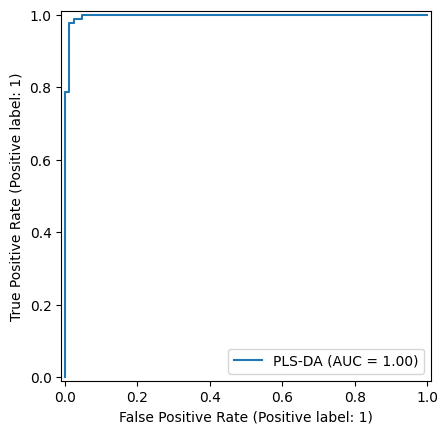

In [11]:
daModel = LogisticRegression()

plsScores = plsModel.transform(X=logXDataMatrix)

# Fit the logistic regression model with the scores
daModel.fit(plsScores, YGenderDummy)

# Obtain the test set scores and the prediction
plsDaClassification = daModel.predict(plsScores)
plsDaProbas = daModel.predict_proba(plsScores)[:, 1]

# ROC curve
RocCurveDisplay.from_estimator(daModel, X=plsScores, y=YGenderDummy, name="PLS-DA")

# Score ROC AUC
"ROC AUC: {0}".format(roc_auc_score(YGenderDummy, plsDaProbas))

_The model seems to perform very well..._

### PLS-DA scores plot
Lets's now examine the PLS scores plot...

In [12]:
T_scores = plsModel.transform(logXDataMatrix)

# Assemble a pandas data frame with the scores for each component and then combine with study variables
plsResultsDFrame = pds.DataFrame(T_scores, columns=['PLS T' + str(x+1) for x in range(T_scores.shape[1])])
plsResultsDFrame = pds.concat([lcMSData.loc[:, ['Sample ID', 'Age', 'Gender', 'Run Order']], plsResultsDFrame], axis=1)

In [13]:
def hotelling_ellipse(scores, alpha=0.05):
    """Return (x, y) coordinates of the 95% Hotelling T² ellipse for component 1 vs 2.

    Uses the chemometrics convention: T²_i = sum_a(t_ia² / var_a),
    with the exact F-distribution critical value:
        T²_crit = A(n-1)(n+1) / (n(n-A)) * F(1-alpha, A, n-A)

    Ellipse semi-axes: sqrt(var_a * T²_crit)
    """
    n = scores.shape[0]
    A = 2  # number of components plotted
    lam = np.var(scores[:, :2], ddof=1, axis=0)
    t2_crit = (A * (n - 1) * (n + 1)) / (n * (n - A)) * f_distribution.ppf(1 - alpha, A, n - A)
    a = np.sqrt(lam[0] * t2_crit)
    b = np.sqrt(lam[1] * t2_crit)
    theta = np.linspace(0, 2 * np.pi, 300)
    return a * np.cos(theta), b * np.sin(theta)

In [14]:
fig = px.scatter(plsResultsDFrame, x="PLS T1", y="PLS T2", color="Gender",
                 render_mode='webgl',
                template='plotly_white')

ex, ey = hotelling_ellipse(T_scores)
fig.add_scatter(x=ex, y=ey, mode='lines',
                line=dict(color='grey', dash='dash'),
                name='95% Hotelling T²')

fig.show()

### Model interpretation and variable importance

The PLS-DA parameters are exactly the same as those in the PLS regression.

The main parameters to assess variable importance in a PLS model are the weights $w$, the loadings $p$, and regression coefficients $\beta$.

- **X-weights (`w` `plsModel['PLS'].x_weights_`)** convey the covariance shared directly by the X variables with Y. Each component has its own weight vector, with values varying between -1 (strong negative-covariance) and 1 (strong covariance), with 0 meaning no association/covariance. The weight vector of the first component (which explains the most variation in Y) is the primary weight vector to analyze when interpreting the main variables of X associed with Y.

- **X-loadings (`p` `plsModel['PLS'].x_loadings_`)** should be used like PCA loadings, to interpret the directions in the PLS score plots. Each PLS component has its own loading vector.

- **Regression coefficients (`B` `plsModel['PLS'].coef_`)** The regression coefficients ($\beta$) have a similar interpretation as regression coefficients in a multivariate/multiple linear regression. There is only one vector of coefficients for the entire model.


In [15]:
w = plsModel['PLS'].x_weights_    # shape (n_features, n_components)
p = plsModel['PLS'].x_loadings_   # shape (n_features, n_components)
B = plsModel['PLS'].coef_         # shape (1, n_features) for binary Y

print('x_weights_ shape:', w.shape)
print('x_loadings_ shape:', p.shape)
print('coef_       shape:', B.shape)

x_weights_ shape: (3221, 2)
x_loadings_ shape: (3221, 2)
coef_       shape: (1, 3221)


In [16]:
for i in range(p.shape[1]):
    fig = px.scatter(featuresData, x='Rt', y='mz',
        color=w[:, i],
        render_mode='webgl',
        color_continuous_scale='RdBu',
        color_continuous_midpoint=0,
        labels={'Rt': 'Retention time (min)', 'mz': 'm/z',
                'color': 'p' + str(i + 1)},
        title='PLS-DA X-weights: component ' + str(i + 1),
        template='plotly_white')
    fig.show()

**Loadings p** A feature with large positive `p_a` is elevated in samples on the positive side of component *a* in the scores plot, and depleted in samples on the negative side.

In [17]:
for i in range(p.shape[1]):
    fig = px.scatter(featuresData, x='Rt', y='mz',
        color=p[:, i],
        render_mode='webgl',
        color_continuous_scale='RdBu',
        color_continuous_midpoint=0,
        labels={'Rt': 'Retention time (min)', 'mz': 'm/z',
                'color': 'p' + str(i + 1)},
        title='PLS-DA X-loadings: component ' + str(i + 1),
        template='plotly_white')
    fig.show()

**Regression coefficients** Red = feature elevated in Male (class 1); blue = elevated in Female (class 0).

In [18]:
fig = px.scatter(featuresData, x='Rt', y='mz',
    color=B[0, :],
    render_mode='webgl',
    color_continuous_scale='RdBu',
    color_continuous_midpoint=0,
    labels={'Rt': 'Retention time (min)', 'mz': 'm/z', 'color': 'B[Male]'},
    title='Regression coefficients: Male vs Female',
    template='plotly_white')
fig.show()

# Model validation

The model ROC curve and ROC AUC values we obtained were very good (ROC AUC > 0.95)!!
But can we trust the discrimination results we obtained? Is PLS that prone to overfitting and over-optimism?

### Model cross-validation

Instead, we will use cross-validation to obtain reliable model performance estimates.

The following code uses a stratified (preserving the % prevalence of each class in the test set) K-Fold cross-validation routine to obtain ROC AUC, f1-score, and r-squared values which were calculated on external test set data (data not used to fit the model).

In [19]:
# Define a function to fit and cross-validate a PLS-DA model
def crossValidate_PLSDA(x, y, n_components=2, scale=True, cv=StratifiedKFold(7, shuffle=True, random_state=42)):

    if scale is True:
        plsModel = Pipeline(steps=[('uv_scale', StandardScaler()),
                                   ('PLS', PLSRegression(n_components=n_components, scale=False))])
    else:
        plsModel = Pipeline(steps=[('PLS', PLSRegression(n_components=n_components, scale=False))])

    daModel = LogisticRegression()

    cvResults = {'roc_auc':[], 'f1':[], 'r2':[]}

    # Iterate through CV rounds
    for trainIdx, testIdx in cv.split(x, y):

        # Fit the PLS model on training set
        plsModel.fit(x[trainIdx, :], y[trainIdx])

        cvResults['r2'].append(r2_score(y[testIdx], plsModel.predict(x[testIdx, :])))
        # Obtain the scores from the training set
        plsTrainScores = plsModel.transform(X=x[trainIdx, :])
        # Fit the logistic regression model with the train set scores and Y train set
        daModel.fit(plsTrainScores, y[trainIdx])

        # Obtain the test set scores and the prediction
        plsTestScores = plsModel.transform(X=x[testIdx, :])
        testPredicted = daModel.predict(plsTestScores)
        testProbas = daModel.predict_proba(plsTestScores)[:, 1]

        # Score ROC AUC (using predicted probabilities) and f1 (using hard predictions)
        cvResults['roc_auc'].append(roc_auc_score(y[testIdx], testProbas))
        cvResults['f1'].append(f1_score(y[testIdx], testPredicted))

    cvResults = {key: np.array(value) for key, value in cvResults.items()}
    return pds.DataFrame(cvResults)

In [20]:
cvResults = crossValidate_PLSDA(logXDataMatrix, YGenderDummy, n_components=2, scale=True, cv=StratifiedKFold(7, shuffle=True, random_state=42))

The result of the 7-Fold CV process is 7 instances of the classifier performance metrics chosen (roc_auc, f1, r2).

In [21]:
cvResults

,roc_auc,f1,r2
0,0.770833,0.692308,0.169615
1,0.965278,0.818182,0.480201
2,0.902778,0.846154,0.498427
3,0.930556,0.869565,0.531145
4,0.923611,0.631579,0.450187
5,0.944444,0.956522,0.608396
6,0.923611,0.818182,0.542676


### Selecting the optimal number of components with cross-validation

Cross-validation should also be used to select the optimal number of components. The CV procedure should be applied to models with a varying number of components, to generate a "scree plot" with cross-validated measures.

In [22]:
maxNComponents = 10

screePLSDA = [crossValidate_PLSDA(logXDataMatrix, YGenderDummy, n_components=x, scale=True, cv=StratifiedKFold(7, shuffle=True, random_state=42)) for x in range(1, maxNComponents + 1)]

In [23]:
cvPLSDA_DFrame = list()

for ncomp, cv in enumerate(screePLSDA):
    currentNComp = pds.DataFrame(cv)
    currentNComp['Ncomp'] = ncomp + 1
    cvPLSDA_DFrame.append(currentNComp)

cvPLSDA_DFrame = pds.concat(cvPLSDA_DFrame, axis=0)

In [24]:
fig = px.box(cvPLSDA_DFrame, x='Ncomp', y='roc_auc', # points="all",
             labels={"Ncomp": "Number of components",
                        "roc_auc": "ROC AUC"}, template='plotly_white')

fig.show()

The gains in model performance after 4 components become marginal, and therefore we will select 4 as the optimal number of components.

### Fit model with optimal number of PLS components

In [25]:
plsModel = Pipeline(steps=[('uv_scale', StandardScaler()),
                                   ('PLS', PLSRegression(n_components=4, scale=False))])

daModel = LogisticRegression()

# Fit the PLS-DA model to the full dataset
plsModel.fit(logXDataMatrix, YGenderDummy)
daModel.fit(plsModel.transform(logXDataMatrix), YGenderDummy)

LogisticRegression()

In [26]:
cvResults = crossValidate_PLSDA(logXDataMatrix, YGenderDummy, n_components=4, scale=True, cv=StratifiedKFold(7, shuffle=True, random_state=42))

These cross-validated metrics are better estimates of the expected model performance.

In [27]:
pds.DataFrame(np.c_[cvResults.mean(), cvResults.std()], columns=['Mean', 'Stdev'], index=cvResults.columns)

,Mean,Stdev
roc_auc,0.953373,0.027695
f1,0.899425,0.054503
r2,0.559269,0.100733


### Permutation randomisation test

A final and very important method for model validation is the permutation randomization test. In a permutation randomisation test, the model will be refitted and assessed multiple times, but each time with the Y randomly permuted to destroy any relationship between X & Y. This allows us to assess what sort of model we can get when there really is no relationship between the two data matrices, and calculate the likelihood of obtaining a model with predictive performance as good as the non-permuted model by chance alone.

During this test, the number of components, scaling, type of cross-validation employed, and any other modeling choice is kept constant. In each randomization, the model is refitted, and the performance and model validation metric recorded. This enables the generation of permuted null distributions for these metrics, which can be used to obtain an empirical p-value for their significance.

**Note**: Running the permutation test with a large number of permutation randomizations (for example, 1000) is expected to take a considerable amount of time (> 30 mins on a laptop).

In [28]:
nPermutations = 250

np.random.seed(42)
permResults = []

for permutation in range(nPermutations):
        # permute the Y vector
        permutedY = np.random.permutation(YGenderDummy)
        # Select the same number of components, and apply cross-validation in the same manner
        permcvResults = crossValidate_PLSDA(logXDataMatrix, permutedY, n_components=4, scale=True, cv=StratifiedKFold(7, shuffle=True))
        permResults.append(permcvResults.mean())

permResults = pds.DataFrame(permResults)

In [36]:
fig = px.histogram(permResults, x='roc_auc', nbins=20)

fig.add_vline(x=cvResults['roc_auc'].mean(), line_dash="dash")
fig.show()
"Permutation p-value ~ {0}".format(np.sum(permResults['roc_auc'] >= cvResults['roc_auc'].mean())/(nPermutations + 1))

'Permutation p-value ~ 0.0'

Histogram of results from permuted (null) models. The vertical line represents the ROC AUC value obtained in the "real" model. **Note**: The numerical precision of the p-value estimate is dependent on the number of permutations used.

In [40]:
predictFrame = pds.DataFrame(np.c_[plsModel.predict(logXDataMatrix), YGender], columns=['Predicted', 'Gender'])

fig = px.scatter(predictFrame, x="Predicted", y="Gender", render_mode='webgl',
                labels={"Predicted": "PLS predicted Gender",
                        "Gender": "Gender"},
                template='plotly_white')

fig.add_vline(x=0.5, line_dash="dash")

fig.show()

### PLS - DA and overfitting

What happens if we try to predict a fake Y dummy vector?

In [41]:
np.random.seed(42)

# Random resampling of the original Y vector
YGenderFake = np.random.permutation(YGenderDummy)

plsModel = Pipeline(steps=[('uv_scale', StandardScaler()), ('PLS', PLSRegression(n_components=2, scale=False))])

plsModel.fit(logXDataMatrix, YGenderFake)

Pipeline(steps=[('uv_scale', StandardScaler()),
                ('PLS', PLSRegression(scale=False))])

In [42]:
T_scores = plsModel.transform(logXDataMatrix)

GenderFakeColumn = pds.Series(YGenderFake).map({0:'Female', 1:'Male'})
# Assemble a pandas data frame with the scores for each component and then combine with study variables
plsResultsDFrame = pds.DataFrame(T_scores, columns=['PLS T' + str(x+1) for x in range(T_scores.shape[1])])
plsResultsDFrame = pds.concat([lcMSData.loc[:, ['Sample ID', 'Age', 'Gender', 'Run Order']], pds.Series(GenderFakeColumn, name='GenderFake'), plsResultsDFrame], axis=1)

In [43]:
fig = px.scatter(plsResultsDFrame, x="PLS T1", y="PLS T2", color="GenderFake",
                 render_mode='webgl',
                template='plotly_white')

ex, ey = hotelling_ellipse(T_scores)
fig.add_scatter(x=ex, y=ey, mode='lines',
                line=dict(color='grey', dash='dash'),
                name='95% Hotelling T²')

fig.show()

... and this is why PLS scores plots cannot be trusted to check a model quality. Separation in a PLS score plot is **NOT** a good measure of model quality.